In [1]:
import fitz
from IPython.display import display, Image

In [2]:
# Directory where individual data cube plots are stored
figsave_path = '/glade/derecho/scratch/jstarfeldt/data_analysis/plots'

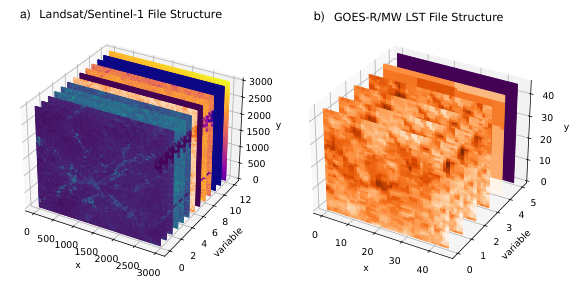

In [11]:
# Create an 8 x 4 inch figure
output = fitz.open()
page = output.new_page(width=288, height=144)

# Open the individual PDF figures
pdf1 = fitz.open(f'{figsave_path}/Landsat_file_structure.pdf')
pdf2 = fitz.open(f'{figsave_path}/GOES_file_structure.pdf')

# Arrange the two PDFs side by side
page.show_pdf_page(
    fitz.Rect(0, 0, 144, 144),
    pdf1, 0, keep_proportion=True
)

page.show_pdf_page(
    fitz.Rect(144, 0, 288, 144),
    pdf2, 0, keep_proportion=True
)

# Add subfigure labels
page.insert_text((10, 9), "a)", fontsize=6)
page.insert_text((157, 10), "b)", fontsize=6)

# Save the combined figure
output.save(f'{figsave_path}/data_structure_figure.pdf')

# Render the combined PDF as an image for visualization
pix = page.get_pixmap(matrix=fitz.Matrix(2, 2), alpha=False)
display(Image(data=pix.tobytes("png")))

# Close PDF documents
pdf1.close()
pdf2.close()
output.close()